# NFL Game Simulator v4

**Keep `nfl_game_sim_v4.py` in the same folder as this notebook. If you replace the .py file, restart the kernel (Kernel → Restart) before running again.**

First run downloads ~170 MB of nflverse data (play-by-play 2019-2026, rosters, depth charts, injury reports, snap counts) into `nfl_data/`. Later runs use the cache. To refresh rosters and injury reports each week, delete `roster_weekly_2026.parquet`, `depth_charts_2026.parquet`, `injuries_2026.parquet`, `pbp_2026.parquet`, `snap_counts_2026.parquet` and `games.csv` from `nfl_data/`.

**How a game is simulated.** Coin toss, then possession by possession on a real 60-minute clock. Each drive starts at an actual field position and ends in a TD, FG, missed FG, punt, turnover, or turnover on downs, with odds and time used drawn from real NFL drives and tilted for the two teams. The next drive starts where the ball ended up: short fields after turnovers, pick-sixes, kickoffs after scores. Field goals sample a real kick distance and use the kicker's accuracy. Ties go to 2025-rules overtime.

| Factor | What it uses |
|---|---|
| Team efficiency | Opponent-adjusted EPA/play (pass and run) blended with points ratings |
| Starting QB | Depth chart QB1 (skips injured/reserve), rated by EPA per dropback; optional 2019-2024 history for veterans |
| QB mistakes | Interceptions + lost fumbles per dropback, drives turnover odds |
| Skill players | WR/TE/RB value above replacement; removed if on IR/PUP/NFI or the injury report; moves with the player on trades |
| Game plan vs similar teams | Pass rate vs defenses built like this opponent; current head coach's games count fully, older regimes 40% |
| Style matchup | Over/under-performance vs similar defenses |
| 4th-down aggressiveness | Head coach go-for-it rate over expected, punt zone and FG zone |
| Halftime adjustments | Coach 2nd-half vs 1st-half efficiency swing |
| Head-to-head | Meetings in the last 2 years, heavily shrunk |
| Weather and roof | Wind over 10 mph, cold below 40F, indoor. Your forecast, else the stadium's monthly average |
| Rest and travel | Rest days, short weeks, West Coast teams in early Eastern kickoffs |
| Pass rush vs protection | Pressure (sacks + QB hits) allowed vs generated, log5 matchup |
| Kicker accuracy | Depth-chart kicker vs league at each distance |
| Red-zone TD rate | TD vs FG finishing inside the 20, heavily shrunk |
| Referee | Crew chief flags per game and home/away flag split |
| OL and defensive starters | Regular starters from snap counts; missing ones (injury report, IR/PUP, trades) vs the team's usual level. Missing OL starter -0.028 EPA/play, missing CB +0.042 for the opponent. Defenders weighted by sacks/QB hits or INTs/passes defended per snap |

Every effect is estimated from data and shrunk by how reliable it is. Factors with no measurable effect still show up in the output notes but barely move the line.

In [67]:
# First time only
# %pip install pandas numpy pyarrow matplotlib

In [80]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from nfl_game_sim_v4 import *

games, pbp, injuries = load_all([2023, 2024, 2025, 2026])
prep = prepare(games, pbp)
del pbp

games, pbp, injuries = load_all([2023, 2024, 2025, 2026])
prep = prepare(games, pbp)
del pbp  # free memory; everything needed is in prep
add_qb_history(prep, range(2019, 2025))       # veteran backups rated on their own history
add_referee_history(prep, range(2019, 2023))  # more games per crew chief
rosters_all = pd.concat([load_rosters(y)[0] for y in (2023, 2024, 2025, 2026)])
add_line_data(prep, [2023, 2024, 2025, 2026], rosters_all, injuries)  # OL / defense starters
print("Data ready.")

Data ready.


## 1. Current rosters, injuries, and ratings
Until the Week 4 injury report comes out (Wed-Fri), the Week 3 report carries forward at reduced weight (Out 70%, Doubtful 50%, Questionable 15%). IR, PUP, NFI, suspended = out.

In [29]:
SEASON, WEEK, AS_OF = 2026, 4, "2026-09-29"
CARRY_FORWARD = True   # True until this week's Friday injury report is out, then False

rosters, depth = load_rosters(SEASON)
ctx = build_context(SEASON, WEEK, rosters, injuries, depth, carry_forward=CARRY_FORWARD)
model = fit_model(prep, AS_OF)

rw = rosters[rosters.week == rosters.week.max()]
print("Reserve lists:", rw[rw.status == "RES"].status_description_abbr.map(RESERVE_LABELS).fillna("other").value_counts().to_dict())

Reserve lists: {'IR': 187, 'IR (designated to return)': 50, 'PUP': 30, 'NFI': 10, 'suspended': 1, 'other': 1}


## 2. Simulate one game
Overrides: `HOME_QB` / `AWAY_QB` force a starter ("Case Keenum" or "C.Keenum"); `OUT` rules players out ("T.Bagent"); `WEATHER` takes a forecast; `REFEREE` sets the crew chief if the assignment isn't in the data yet (full name, e.g. "Shawn Hochuli").

PHI (J.Hurts) @ CHI (T.Taylor)
  Win prob:    CHI 54.1% | PHI 45.1% | tie 0.8%
  Final proj:  CHI 23.9 - PHI 22.3   (halftime 10.3 - 11.8)
  Line:        CHI -1.5   Total 46.2
  Possessions: CHI 10.9, PHI 10.9   Turnovers: CHI 1.23, PHI 1.16
  Most likely finals: CHI 27 - PHI 20 (0.8%), CHI 17 - PHI 20 (0.7%), CHI 24 - PHI 20 (0.7%)
  Conditions:  ~71F, wind ~8 mph (stadium average, no forecast) (total -0.1) | rest: CHI 8 days, PHI 8 days | PHI crosses 1 time zone(s) (CHI -0.1)
  Referee:     crew not assigned yet (assignments come out mid-week) (CHI +0.00)
  CHI offense: C.Santos (52/62, -0.01 vs avg) | QB pressured 14.0% of dropbacks (league 15.5%) | red-zone TD 58.6% (league 58.3%)
  PHI offense: J.Elliott (62/78, -0.18 vs avg) | QB pressured 13.8% of dropbacks (league 15.5%) | red-zone TD 59.8% (league 58.3%)


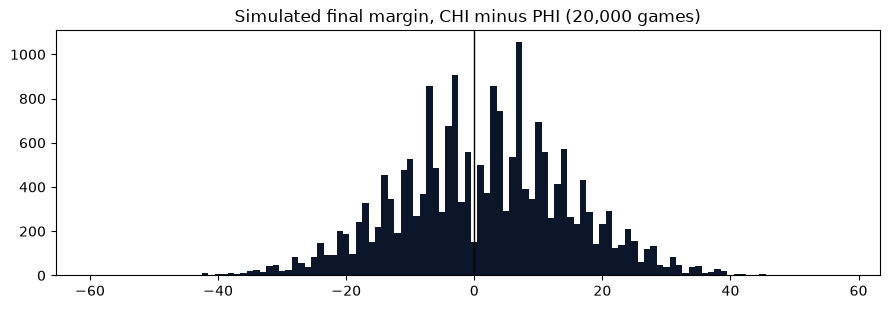

In [96]:
HOME, AWAY, NEUTRAL = "CHI", "PHI", False
HOME_QB, AWAY_QB, OUT = "T.Taylor", None, ["T.Bagent"]
WEATHER = None   # e.g. {"temp": 38, "wind": 18}
REFEREE = None

result = simulate_game(model, HOME, AWAY, n_sims=20000, neutral=NEUTRAL, seed=42, home_qb=HOME_QB,
                       away_qb=AWAY_QB, out_players=OUT, ctx=ctx, weather=WEATHER, referee=REFEREE)
print_game(result)

margin = result["home_scores"] - result["away_scores"]
plt.figure(figsize=(9, 3.2))
plt.hist(margin, bins=np.arange(margin.min() - .5, margin.max() + 1.5), color="#0B162A")
plt.axvline(0, color="black", lw=1)
plt.title(f"Simulated final margin, {HOME} minus {AWAY} (20,000 games)")
plt.tight_layout(); plt.show()

### OL and defensive starters
Regular starters (snap share when they play), quality multiplier for defenders, and who's missing.

In [43]:
line_status(model, prep, HOME, ctx, OUT)

,player,group,snap_share,quality,missing_weight,why
12,Dillon Thieneman,CB,1.00,1.08,0.0,
5,Jaylon Johnson,CB,0.98,0.96,0.0,
7,Cameron Lewis,CB,0.88,0.79,0.0,
10,Tyrique Stevenson,CB,0.83,1.51,0.0,
8,Malik Muhammad,CB,0.69,1.39,0.0,
4,Grady Jarrett,DL,0.68,0.88,0.0,
11,Montez Sweat,DL,0.66,1.69,0.0,
9,Dayo Odeyingbo,DL,0.61,1.31,0.0,
2,T.J. Edwards,LB,1.00,1.00,0.0,
1,Devin Bush Jr.,LB,0.98,1.00,0.0,


In [44]:
line_status(model, prep, AWAY, ctx, OUT)

,player,group,snap_share,quality,missing_weight,why
3,Cooper DeJean,CB,1.00,1.13,0.0,
9,Quinyon Mitchell,CB,1.00,1.30,0.0,
2,Jalen Carter,DL,0.85,1.19,0.0,
11,Moro Ojomo,DL,0.75,0.87,0.0,
0,Zack Baun,LB,1.00,1.00,0.0,
1,Jihaad Campbell,LB,0.93,1.00,0.0,
5,Jalyx Hunt,LB,0.78,1.97,0.0,
12,Nolan Smith,LB,0.72,1.92,0.0,
6,Lane Johnson,OL,1.00,1.00,0.0,
7,Cam Jurgens,OL,1.00,1.00,0.0,


### What moved the line
Factors added one at a time.

In [45]:
factor_breakdown(model, HOME, AWAY, ctx=ctx, home_qb=HOME_QB, away_qb=AWAY_QB, out_players=OUT, weather=WEATHER, referee=REFEREE)

,factor added,CHI margin,change,CHI win %
0,Team points ratings only,3.4,0.0,59.3
1,EPA efficiency (pass/run),2.4,-1.0,57.8
2,Starting QB,-0.2,-2.6,48.8
3,Skill players out,-0.2,0.0,49.0
4,Game plan vs similar D,-0.1,0.0,48.8
5,Style matchup residual,0.4,0.6,51.3
6,Turnover tendencies / QB mistakes,0.2,-0.2,50.8
7,4th-down aggressiveness,0.6,0.3,51.0
8,Halftime adjustments,0.7,0.1,51.2
9,Head-to-head (2 yrs),0.8,0.1,52.1


## 3. Full week vs. Vegas
Negative line = home team favored.

In [46]:
simulate_week(model, SEASON, WEEK, ctx=ctx)

,matchup,QBs,home_win_%,model_line,vegas_line,model_total,vegas_total
0,PIT @ CLE,A.Rodgers / D.Watson,49.9,-0.1,2.5,42.8,38.5
1,IND @ WAS,D.Jones / M.Mariota,49.2,0.1,3.0,53.3,47.5
2,TEN @ BAL,C.Ward / L.Jackson,70.0,-7.3,-11.5,46.4,43.5
3,NE @ BUF,D.Maye / J.Allen,59.7,-3.4,-7.0,49.9,48.5
4,NYJ @ CHI,G.Smith / T.Bagent,64.4,-5.3,-3.0,45.0,42.5
5,JAX @ CIN,T.Lawrence / J.Burrow,37.3,4.3,-2.5,49.8,51.5
6,DAL @ HOU,D.Prescott / C.Stroud,55.1,-1.7,-2.5,51.1,47.5
7,ARI @ NYG,J.Brissett / J.Winston,65.6,-5.5,1.5,46.6,44.5
8,LA @ PHI,M.Stafford / J.Hurts,52.3,-0.9,1.5,46.6,46.5
9,GB @ TB,J.Love / B.Mayfield,55.9,-2.2,3.5,50.7,39.5


## 4. Coach, QB, and referee tendencies
`4th_GOE` = go-for-it rate above an average coach in the same spot. Halftime swings are in EPA/play, heavily shrunk.

In [47]:
coach_table(model)

,coach,4th_GOE_punt_zone,4th_GOE_fg_zone,halftime_off_swing,halftime_def_swing
team,,,,,
DAL,Brian Schottenheimer,0.128,0.041,-0.031,0.023
IND,Shane Steichen,0.093,0.015,-0.015,-0.026
CAR,Dave Canales,0.070,-0.006,0.028,0.027
BUF,Sean McDermott,0.064,0.153,0.020,0.049
DET,Dan Campbell,0.059,0.168,0.010,-0.037
ATL,Raheem Morris,0.042,0.008,-0.010,-0.021
KC,Andy Reid,0.042,-0.075,0.005,0.004
NYG,John Harbaugh,0.041,0.005,0.052,-0.038
PHI,Nick Sirianni,0.039,0.068,-0.053,-0.017


In [87]:
_, pbp26, _ = load_all([2026])

d = pbp26[(pbp26["week"].between(1, 2)) & (pbp26["qb_dropback"] == 1)]

w12 = (
    d.assign(to=d["interception"].fillna(0) + d["fumble_lost"].fillna(0))
     .groupby("id")
     .agg(name=("name", "first"),
          team=("posteam", "last"),
          db=("epa", "size"),
          epa_db=("epa", "mean"),
          to_db=("to", "mean"))
)

out = w12[w12["db"] >= 40].copy()
out["to_pct"] = (out["to_db"] * 100).round(3)

out.sort_values(["to_pct", "epa_db"], ascending=[True, False]).head(32)

,name,team,db,epa_db,to_db,to_pct
id,,,,,,
00-0034857,J.Allen,BUF,71,0.531373,0.000000,0.000
00-0035704,D.Lock,SEA,51,0.475840,0.000000,0.000
00-0039910,J.Daniels,WAS,62,0.179797,0.000000,0.000
00-0030565,G.Smith,NYJ,74,0.178655,0.000000,0.000
00-0032950,C.Wentz,MIN,48,0.096375,0.000000,0.000
00-0040676,C.Ward,TEN,63,-0.056232,0.000000,0.000
00-0033106,J.Goff,DET,85,0.220010,0.011765,1.176
00-0033873,P.Mahomes,KC,84,0.176032,0.011905,1.190
00-0036442,J.Burrow,CIN,73,-0.025783,0.013699,1.370


In [84]:
_, pbp26, _ = load_all([2026])

d = pbp26[(pbp26["week"].between(1, 2)) & (pbp26["qb_dropback"] == 1)]

w12 = (
    d.assign(to=d["interception"].fillna(0) + d["fumble_lost"].fillna(0))
     .groupby("id")
     .agg(name=("name", "first"),
          team=("posteam", "last"),
          db=("epa", "size"),
          epa_db=("epa", "mean"),
          to_db=("to", "mean"))
)

w12[w12["db"] >= 40].sort_values("epa_db", ascending=False).head(32)

,name,team,db,epa_db,to_db
id,,,,,
00-0037834,B.Purdy,SF,61,0.556138,0.016393
00-0034857,J.Allen,BUF,71,0.531373,0.000000
00-0035704,D.Lock,SEA,51,0.475840,0.000000
00-0033077,D.Prescott,DAL,72,0.388269,0.013889
00-0039918,C.Williams,CHI,70,0.314496,0.028571
00-0039150,B.Young,CAR,80,0.303267,0.025000
00-0036971,T.Lawrence,JAX,55,0.271026,0.018182
00-0034796,L.Jackson,BAL,66,0.258066,0.030303
00-0033106,J.Goff,DET,85,0.220010,0.011765


In [88]:
print(f"Referee effect per extra flag/game on total points: {model['ref_total_coef']:+.2f} (t = {model['ref_total_t']:.2f})")
print(f"Referee effect of home/away flag split on margin: {model['ref_margin_coef']:+.2f} (t = {model['ref_margin_t']:.2f})")
active_referees(model)

Referee effect per extra flag/game on total points: -0.00 (t = -0.57)
Referee effect of home/away flag split on margin: +0.00 (t = 0.56)


,games,flags_pg,away_minus_home_flags
referee,,,
Adrian Hill,117,12.69,0.62
Alan Eck,53,11.24,0.23
Alex Kemp,120,12.56,0.59
Alex Moore,19,13.83,0.62
Bill Vinovich,121,11.10,0.28
Brad Allen,117,11.61,0.62
Brad Rogers,111,12.36,0.09
Carl Cheffers,120,12.46,0.48
Clay Martin,116,11.83,0.41


## 5. Backtest vs. Vegas (~8 minutes)
Each week: refit using only earlier games, that week's roster and injury report, the actual starting QBs, then grade against the result and the Vegas closing line.

- **Winner %**: picked the right winner. **Spread/total miss**: average points off.
- **ATS**: model takes the side it likes relative to the Vegas spread. Break-even at standard -110 odds is **52.4%**.
- **O/U**: same idea for the total.
- **p-value**: chance a coin flip does at least this well. Under 0.05 starts to mean something; above that is noise.

Note: backtests use actual game-day weather, which is a little better than the forecast you'd have had before kickoff.

In [94]:
RUNS = [(2026, [1, 2]), (2025, None), (2024, None)]
results, details = {}, {}
for yr, wks in RUNS:
    rw_y = load_rosters(yr)[0]
    bt, _ = backtest(games, prep, injuries, rw_y, yr, n_sims=4000, weeks=wks)
    label = f"{yr} wk {wks[0]}-{wks[-1]}" if wks else f"{yr} wk 4+"
    results[label], details[label] = grade_vs_vegas(bt), bt
summary = pd.DataFrame(results)
summary

,2026 wk 1-2,2025 wk 4+,2024 wk 4+
games,32,224,224
winner_pct_model,0.65625,0.605381,0.727679
winner_pct_vegas,0.71875,0.632287,0.741071
spread_miss_model,11.854633,10.303384,10.036391
spread_miss_vegas,11.5625,9.924107,9.276786
total_miss_model,12.800195,10.238328,9.971578
total_miss_vegas,11.1875,9.9375,9.71875
ATS_record,15-16,112-111,99-122
ATS_pct,0.483871,0.502242,0.447964
ATS_p_value,0.63995,0.5,0.946887


In [95]:
ats_detail(details['2026 wk 1-2'])

,week,game,model_line,vegas_line,actual_margin,ATS_pick,ATS,model_total,vegas_total,actual_total,OU_pick,OU
0,1,NE@SEA,-3.0,-3.0,3.0,NE,push,38.7,44.5,23.0,under,W
1,1,SF@LA,-1.7,-3.5,-20.0,SF,W,59.4,47.5,34.0,over,L
2,1,CHI@CAR,3.3,3.0,-22.0,CHI,W,46.4,47.5,96.0,under,L
3,1,TB@CIN,-4.2,-3.5,6.0,CIN,W,50.9,50.5,60.0,over,W
4,1,NO@DET,-1.1,-7.0,1.0,NO,W,47.9,49.5,61.0,under,L
5,1,BUF@HOU,-1.4,1.5,-5.0,HOU,L,51.3,44.5,67.0,over,W
6,1,BAL@IND,3.3,3.0,-18.0,BAL,W,53.5,48.5,64.0,over,W
7,1,CLE@JAX,-4.8,-8.5,24.0,CLE,L,43.7,40.5,44.0,over,W
8,1,ATL@PIT,-2.9,-6.5,7.0,ATL,L,46.7,40.5,33.0,over,L
9,1,NYJ@TEN,-0.9,-1.5,-13.0,NYJ,W,48.0,39.5,33.0,over,L
